<a href="https://colab.research.google.com/github/naveen-pixel07/ML_2/blob/main/Data_handling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
# Replace 'your_dataset.csv' with the actual path to your dataset
try:
    df = pd.read_csv('dataset.csv')
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: 'dataset.csv' not found. Please upload your dataset or provide the correct path.")
    df = pd.DataFrame() # Create an empty DataFrame to avoid errors downstream

# Display the first 5 rows of the DataFrame
if not df.empty:
    display(df.head())

Dataset loaded successfully.


,Series_reference,Period,Data_value,Suppressed,STATUS,UNITS,Magnitude,Subject,Group,Series_title_1,Series_title_2,Series_title_3,Series_title_4,Series_title_5
0,BDCQ.SEA1AA,2011.06,80078.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
1,BDCQ.SEA1AA,2011.09,78324.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
2,BDCQ.SEA1AA,2011.12,85850.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
3,BDCQ.SEA1AA,2012.03,90743.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
4,BDCQ.SEA1AA,2012.06,81780.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN


In [13]:
# Check for missing values and perform cleaning
if not df.empty:
    print("\nMissing values before cleaning:")
    missing_values = df.isnull().sum()
    missing_percentage = (missing_values / len(df)) * 100
    missing_info = pd.DataFrame({
        'Missing Count': missing_values,
        'Missing Percentage': missing_percentage
    })
    display(missing_info[missing_info['Missing Count'] > 0].sort_values(by='Missing Percentage', ascending=False))

    # --- Cleaning Strategy Implementation ---
    # 1. Drop columns with very high missing percentages (e.g., > 70%)
    cols_to_drop = missing_info[missing_info['Missing Percentage'] > 70].index.tolist()
    print(f"\nDropping columns: {cols_to_drop}")
    df_cleaned = df.drop(columns=cols_to_drop)

    # 2. Impute 'Data_value' with its median
    if 'Data_value' in df_cleaned.columns and df_cleaned['Data_value'].isnull().any():
        median_data_value = df_cleaned['Data_value'].median()
        print(f"Imputing missing 'Data_value' with median: {median_data_value}")
        df_cleaned['Data_value'] = df_cleaned['Data_value'].fillna(median_data_value)

    # Update df to df_cleaned for subsequent steps
    df = df_cleaned.copy()

    print("\nMissing values after cleaning:")
    missing_values_after = df.isnull().sum()
    missing_info_after = pd.DataFrame({
        'Missing Count': missing_values_after,
        'Missing Percentage': (missing_values_after / len(df)) * 100
    })
    display(missing_info_after[missing_info_after['Missing Count'] > 0].sort_values(by='Missing Percentage', ascending=False))
    print(f"Original shape: {df.shape}, Cleaned shape: {df.shape}")

else:
    print("DataFrame is empty, skipping cleaning.")


Missing values before cleaning:


,Missing Count,Missing Percentage



Dropping columns: []

Missing values after cleaning:


,Missing Count,Missing Percentage


Original shape: (26446, 11), Cleaned shape: (26446, 11)


In [14]:
if not df.empty:
    print("\nDescriptive statistics:")
    display(df.describe())

    print("\nInformation about data types and non-null values:")
    display(df.info())
else:
    print("DataFrame is empty, skipping summary statistics.")


Descriptive statistics:


,Period,Data_value,Magnitude
count,26446.000000,2.644600e+04,26446.000000
mean,2018.153857,6.773300e+04,2.242683
std,4.357060,2.036584e+05,2.902893
min,2011.060000,1.171797e+00,0.000000
25%,2014.120000,2.612017e+03,0.000000
50%,2018.060000,1.430100e+04,0.000000
75%,2022.030000,4.769900e+04,6.000000
max,2026.060000,2.321295e+06,6.000000



Information about data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26446 entries, 0 to 26445
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Series_reference  26446 non-null  object 
 1   Period            26446 non-null  float64
 2   Data_value        26446 non-null  float64
 3   STATUS            26446 non-null  object 
 4   UNITS             26446 non-null  object 
 5   Magnitude         26446 non-null  int64  
 6   Subject           26446 non-null  object 
 7   Group             26446 non-null  object 
 8   Series_title_1    26446 non-null  object 
 9   Series_title_2    26446 non-null  object 
 10  Series_title_3    26446 non-null  object 
dtypes: float64(2), int64(1), object(8)
memory usage: 2.2+ MB


None

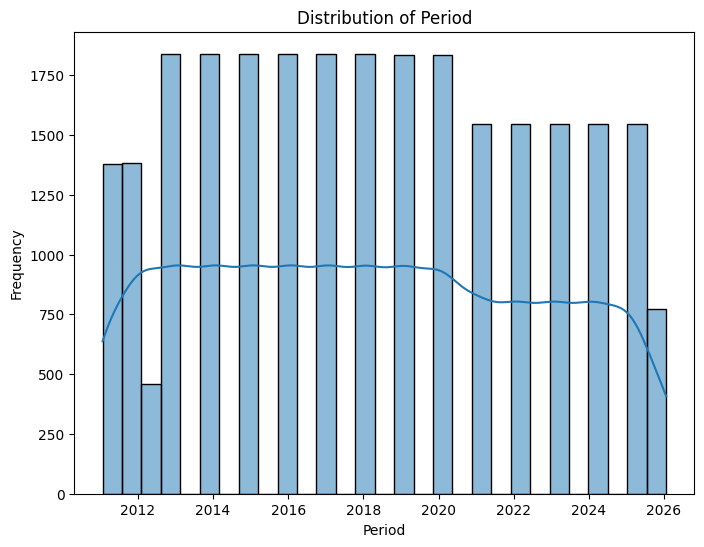

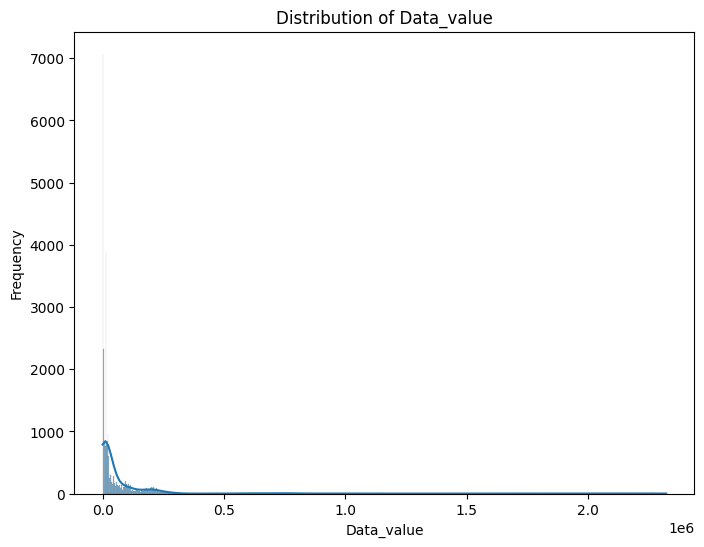

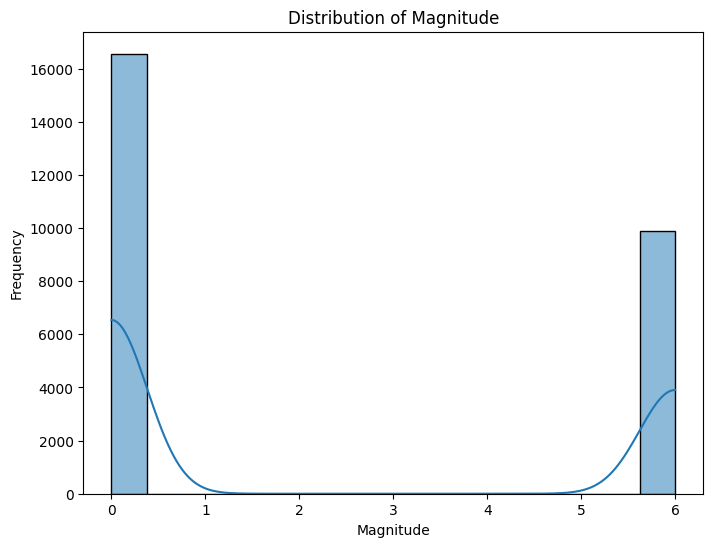

In [16]:
if not df.empty:
    numerical_cols = df.select_dtypes(include=np.number).columns
    if not numerical_cols.empty:
        for col in numerical_cols:
            plt.figure(figsize=(8, 6))
            sns.histplot(df[col], kde=True) # Use df[col] directly as NaNs were handled
            plt.title(f'Distribution of {col}')
            plt.xlabel(col)
            plt.ylabel('Frequency')
            plt.show()
    else:
        print("No numerical columns found for distribution plots.")
else:
    print("DataFrame is empty, skipping distribution plots.")

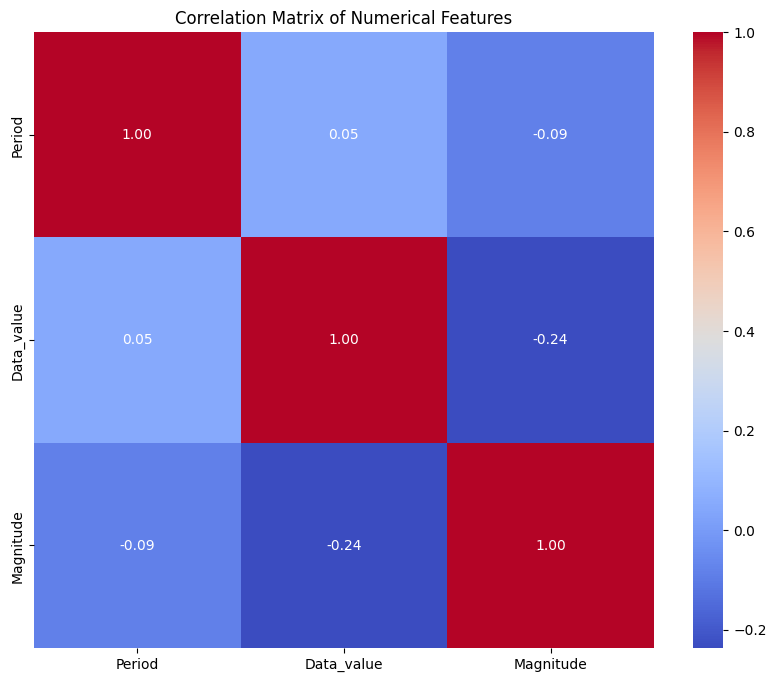

In [15]:
if not df.empty:
    numerical_cols = df.select_dtypes(include=np.number).columns
    if len(numerical_cols) > 1:
        plt.figure(figsize=(10, 8))
        correlation_matrix = df[numerical_cols].corr()
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
        plt.title('Correlation Matrix of Numerical Features')
        plt.show()
    elif len(numerical_cols) == 1:
        print("Only one numerical column found. Correlation heatmap requires at least two numerical columns.")
    else:
        print("No numerical columns found for correlation heatmap.")
else:
    print("DataFrame is empty, skipping correlation heatmap.")